<a href="https://colab.research.google.com/github/Rohith06-luf/AppDevelopment/blob/main/EDA_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rohith M
24AD095

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data=pd.read_csv("/content/drive/MyDrive/StudentPerformanceFactors.csv")
data

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [4]:
data.shape

(6607, 20)

In [5]:
print("\nColumn names:")
print(data.columns.tolist())

print("\nData types:")
print(data.dtypes)


Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Data types:
Hours_Studied                  int64
Attendance                     int64
Parental_Involvement          object
Access_to_Resources           object
Extracurricular_Activities    object
Sleep_Hours                    int64
Previous_Scores                int64
Motivation_Level              object
Internet_Access               object
Tutoring_Sessions              int64
Family_Income                 object
Teacher_Quality               object
School_Type                   object
Peer_Influence                object
Physical_Activity              int64
Learning_Disabilities    

### Missing values

In [6]:
missing = data.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage (%)": (missing / len(data) * 100).round(2)
})

display(missing_summary[missing_summary["Missing Values"] > 0])

,Missing Values,Missing Percentage (%)
Teacher_Quality,78,1.18
Parental_Education_Level,90,1.36
Distance_from_Home,67,1.01


In [7]:
categorical_cols = [
    col for col in ["Teacher_Quality", "Parental_Education_Level","Distance_from_Home"]
    if col in data.columns
]

for col in categorical_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

### Duplicates

In [8]:
data = data.drop_duplicates()

print("Dataset shape after removing duplicates:", data.shape)
print("Remaining duplicate rows:", data.duplicated().sum())

Dataset shape after removing duplicates: (6607, 20)
Remaining duplicate rows: 0


### Visualisation

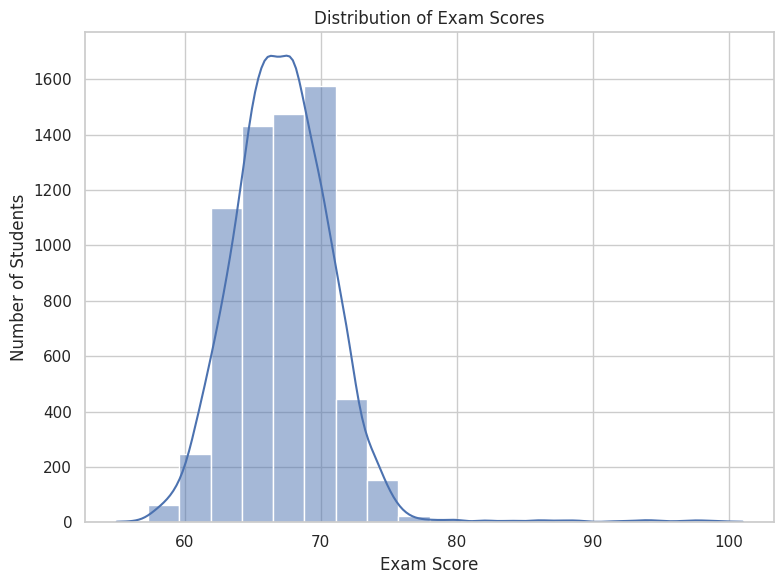

In [9]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.histplot(data=data,x="Exam_Score",bins=20,kde=True)
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

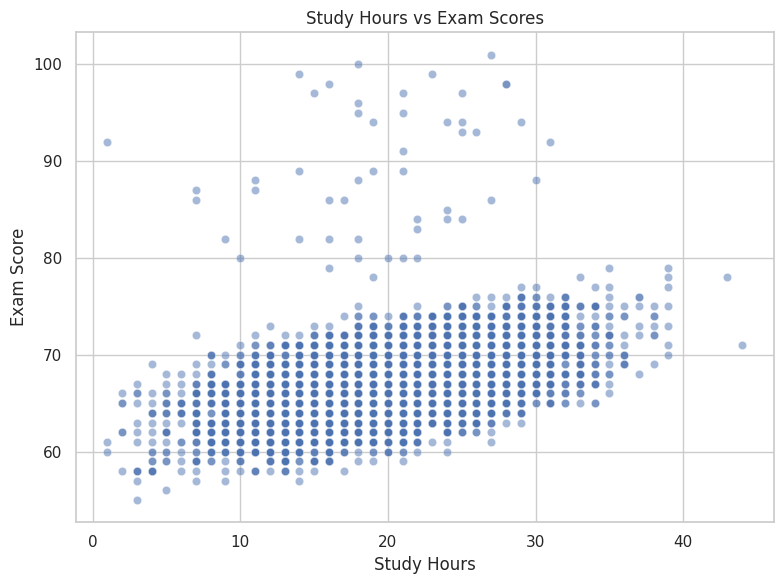

In [10]:
#Study hours vs Exam Scores

plt.figure(figsize=(8,6))
sns.scatterplot(data=data,x="Hours_Studied",y="Exam_Score",alpha=0.5  )
plt.title("Study Hours vs Exam Scores")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

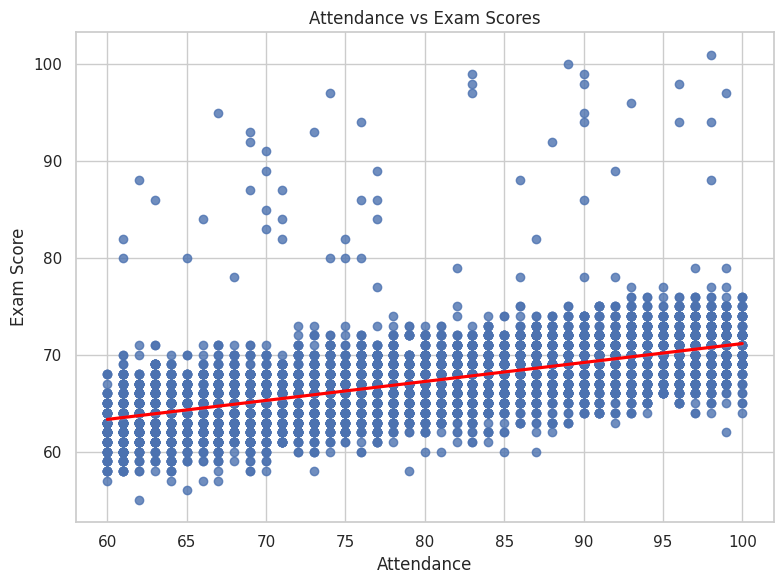

In [11]:
#Attendance  vs Exam_score
plt.figure(figsize=(8,6))
sns.regplot(data=data,x="Attendance",y="Exam_Score",line_kws={"color":"red"})
plt.title("Attendance vs Exam Scores")
plt.xlabel("Attendance")
plt.ylabel("Exam Score")
plt.tight_layout()
plt.show

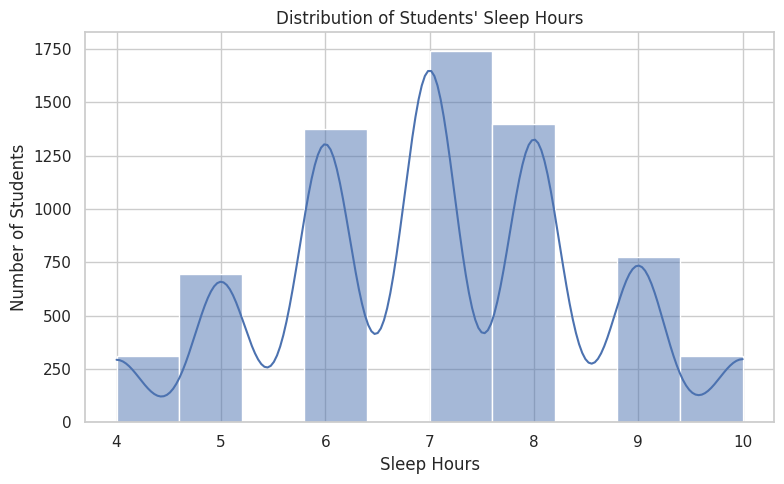

In [12]:
#Sleep Hours Distribution

plt.figure(figsize=(8, 5))
sns.histplot(data=data, x="Sleep_Hours", bins=10, kde=True)

plt.title("Distribution of Students' Sleep Hours")
plt.xlabel("Sleep Hours")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


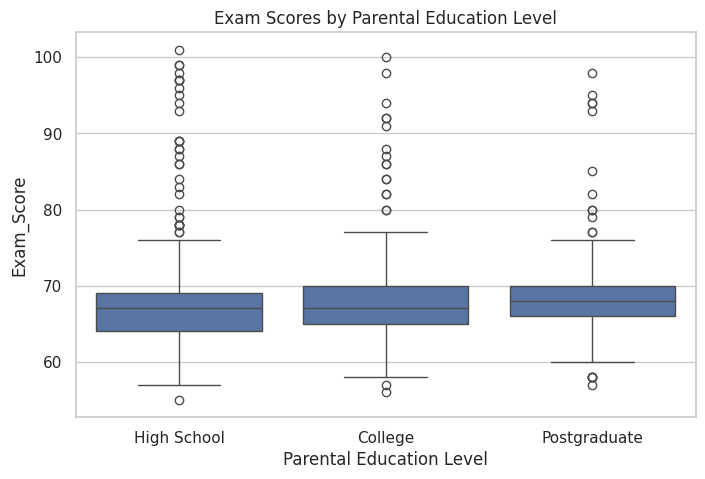

In [13]:
#ExamScores by Parental Education level
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="Parental_Education_Level", y="Exam_Score")

plt.title("Exam Scores by Parental Education Level")
plt.xlabel("Parental Education Level")
plt.show()

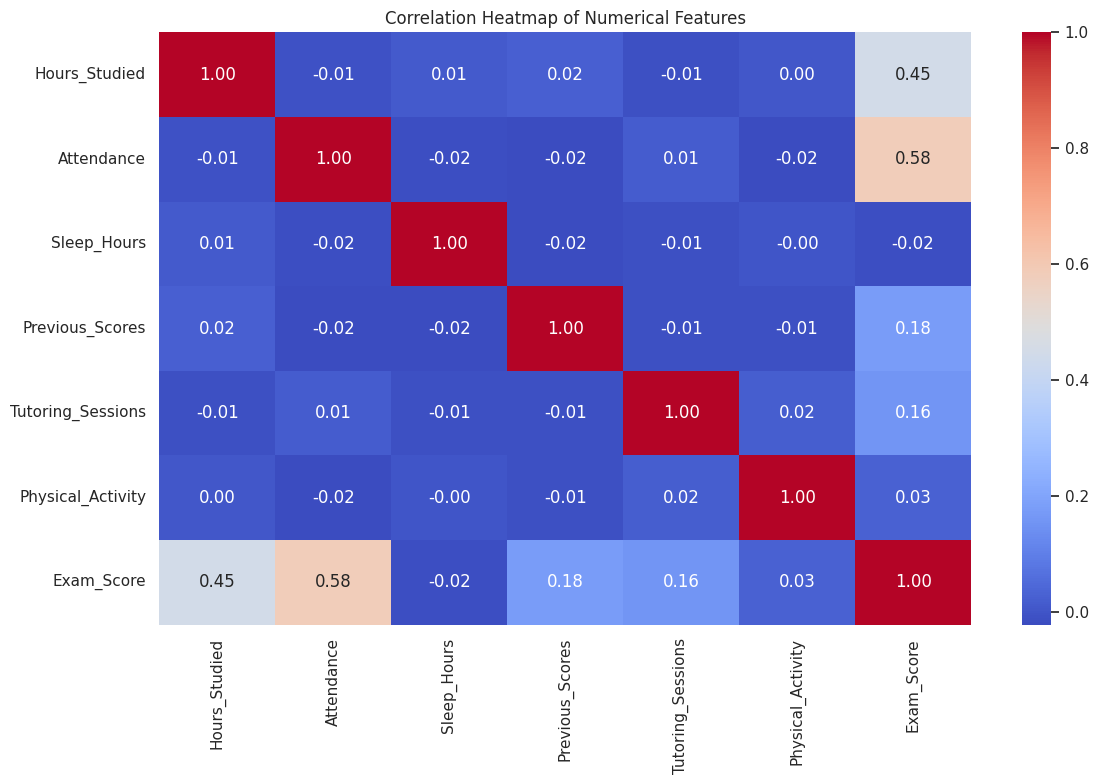

In [14]:
#Correlation

numeric_data = data.select_dtypes(include="number")

plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


### Statistics

In [15]:
numeric_data = data.select_dtypes(include="number")

stats = pd.DataFrame(index=numeric_data.columns)

stats["Mean"] = numeric_data.mean()
stats["Median"] = numeric_data.median()
stats["Mode"] = numeric_data.mode().iloc[0]
stats["Std_Dev"] = numeric_data.std()
stats["Variance"] = numeric_data.var()
stats["Skewness"] = numeric_data.skew()
stats["Kurtosis"] = numeric_data.kurtosis()
stats["Minimum"] = numeric_data.min()
stats["Maximum"] = numeric_data.max()

display(stats.round(2))


,Mean,Median,Mode,Std_Dev,Variance,Skewness,Kurtosis,Minimum,Maximum
Hours_Studied,19.98,20.0,20,5.99,35.89,0.01,0.02,1,44
Attendance,79.98,80.0,67,11.55,133.34,0.01,-1.19,60,100
Sleep_Hours,7.03,7.0,7,1.47,2.16,-0.02,-0.50,4,10
Previous_Scores,75.07,75.0,66,14.40,207.35,-0.00,-1.19,50,100
Tutoring_Sessions,1.49,1.0,1,1.23,1.51,0.82,0.64,0,8
Physical_Activity,2.97,3.0,3,1.03,1.06,-0.03,-0.06,0,6
Exam_Score,67.24,67.0,68,3.89,15.14,1.64,10.58,55,101


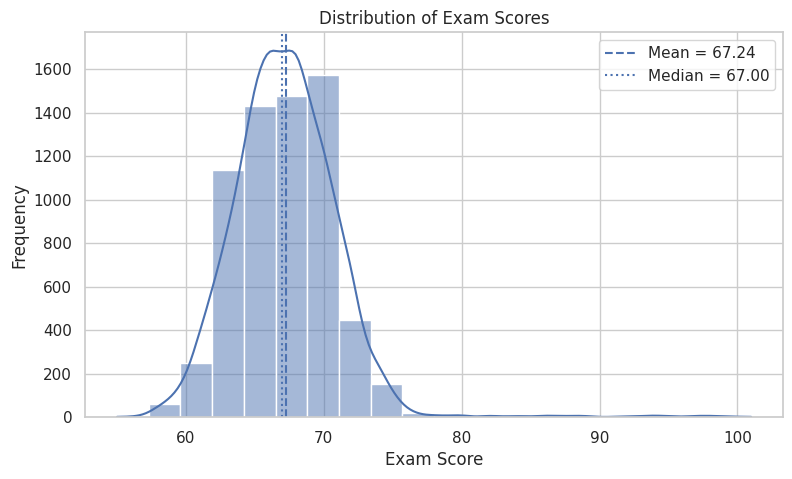

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

exam_mean = data["Exam_Score"].mean()
exam_median = data["Exam_Score"].median()

plt.figure(figsize=(9, 5))
sns.histplot(data["Exam_Score"], bins=20, kde=True)

plt.axvline(exam_mean, linestyle="--",
            label=f"Mean = {exam_mean:.2f}")
plt.axvline(exam_median, linestyle=":",
            label=f"Median = {exam_median:.2f}")

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")
plt.legend()


**### Correlation Analysis**

The correlation analysis examined the linear relationships between numerical student-related factors and exam scores. Attendance showed the strongest positive correlation with exam scores (\(r = 0.581\)), followed by hours studied (\(r = 0.445\)). Previous scores (\(r = 0.175\)) and tutoring sessions (\(r = 0.157\)) exhibited weak positive relationships. Physical activity had a very weak positive correlation (\(r = 0.028\)), while sleep hours showed a negligible negative correlation (\(r = -0.017\)). These findings suggest that attendance and study time are more strongly associated with exam scores than the other numerical features examined. However, correlation does not establish causation, and these results describe only the relationships present in this dataset.

In [17]:
categorical_cols = data.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", categorical_cols)


for col in categorical_cols:
    print(f"\nDistribution of {col}:")
    display(data[col].value_counts().to_frame("Frequency"))

Categorical columns: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Distribution of Parental_Involvement:


,Frequency
Parental_Involvement,
Medium,3362
High,1908
Low,1337



Distribution of Access_to_Resources:


,Frequency
Access_to_Resources,
Medium,3319
High,1975
Low,1313



Distribution of Extracurricular_Activities:


...

,Frequency
Parental_Education_Level,
High School,3313
College,1989
Postgraduate,1305



Distribution of Distance_from_Home:


,Frequency
Distance_from_Home,
Near,3951
Moderate,1998
Far,658



Distribution of Gender:


,Frequency
Gender,
Male,3814
Female,2793


In [18]:

# Compare exam scores across categorical groups

selected_columns = [
    "Parental_Involvement",
    "Teacher_Quality",
    "Motivation_Level",
    "School_Type",
    "Peer_Influence",
    "Family_Income",
    "Distance_from_Home",
    "Parental_Education_Level"
]

for col in selected_columns:
    print(f"\nAverage Exam Score by {col}")

    result = data.groupby(col)["Exam_Score"].agg(
        ["count", "mean", "median", "std"]
    ).round(2)

    display(result)



Average Exam Score by Parental_Involvement


,count,mean,median,std
Parental_Involvement,,,,
High,1908,68.09,68.0,3.95
Low,1337,66.36,66.0,3.97
Medium,3362,67.10,67.0,3.73



Average Exam Score by Teacher_Quality


,count,mean,median,std
Teacher_Quality,,,,
High,1947,67.68,68.0,3.98
Low,657,66.75,67.0,3.87
Medium,4003,67.10,67.0,3.83



Average Exam Score by Motivation_Level


...

,count,mean,median,std
Family_Income,,,,
High,1269,67.84,68.0,4.16
Low,2672,66.85,67.0,3.80
Medium,2666,67.33,67.0,3.81



Average Exam Score by Distance_from_Home


,count,mean,median,std
Distance_from_Home,,,,
Far,658,66.46,66.0,4.14
Moderate,1998,66.98,67.0,3.79
Near,3951,67.49,67.0,3.87



Average Exam Score by Parental_Education_Level


,count,mean,median,std
Parental_Education_Level,,,,
College,1989,67.32,67.0,3.83
High School,3313,66.90,67.0,3.96
Postgraduate,1305,67.97,68.0,3.69


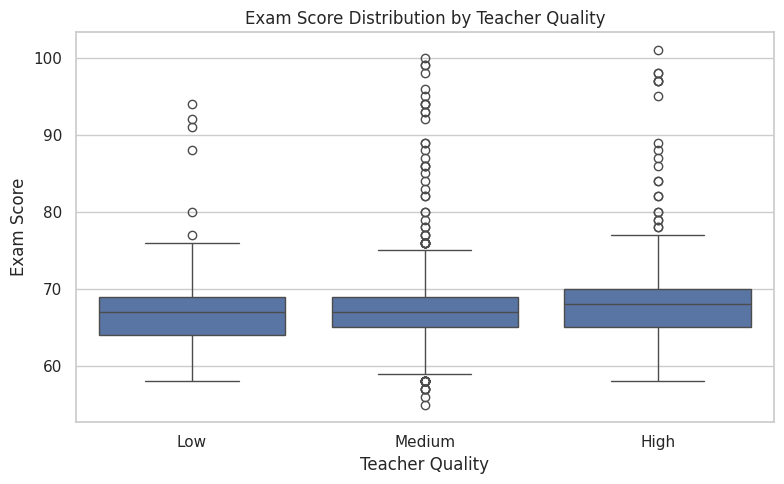

In [20]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Teacher_Quality",
    y="Exam_Score",
    order=["Low", "Medium", "High"]
)

plt.title("Exam Score Distribution by Teacher Quality")
plt.xlabel("Teacher Quality")
plt.ylabel("Exam Score")
plt.tight_layout()
plt.show()


,Frequency,Probability
Tutoring Sessions,,
0,1513,0.2290
1,2179,0.3298
2,1649,0.2496
3,836,0.1265
4,301,0.0456
5,103,0.0156
6,18,0.0027
7,7,0.0011
8,1,0.0002


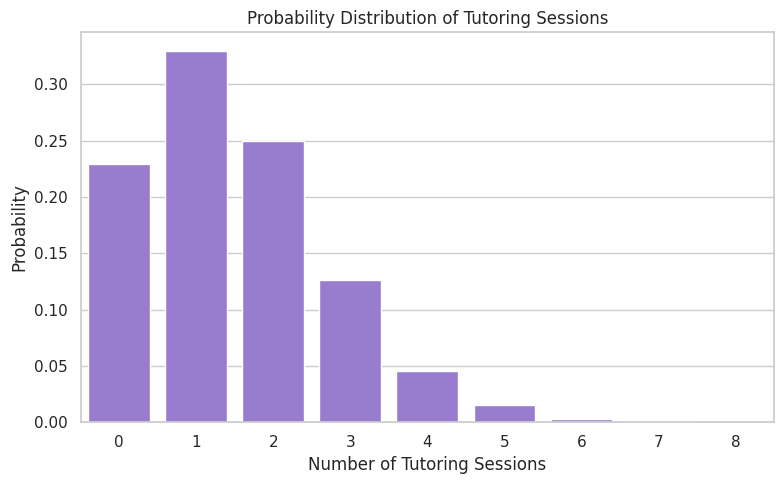

Sum of probabilities: 1.0


In [22]:

# Frequency and probability distribution of tutoring sessions

tutoring_prob = (
    data["Tutoring_Sessions"]
    .value_counts()
    .sort_index()
    .rename_axis("Tutoring Sessions")
    .to_frame("Frequency")
)

tutoring_prob["Probability"] = (
    tutoring_prob["Frequency"] / tutoring_prob["Frequency"].sum()
)

display(tutoring_prob.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(
    x=tutoring_prob.index,
    y=tutoring_prob["Probability"],
    color="mediumpurple"
)

plt.title("Probability Distribution of Tutoring Sessions")
plt.xlabel("Number of Tutoring Sessions")
plt.ylabel("Probability")
plt.tight_layout()
plt.show()

print(
    "Sum of probabilities:",
    round(tutoring_prob["Probability"].sum(), 4)
)


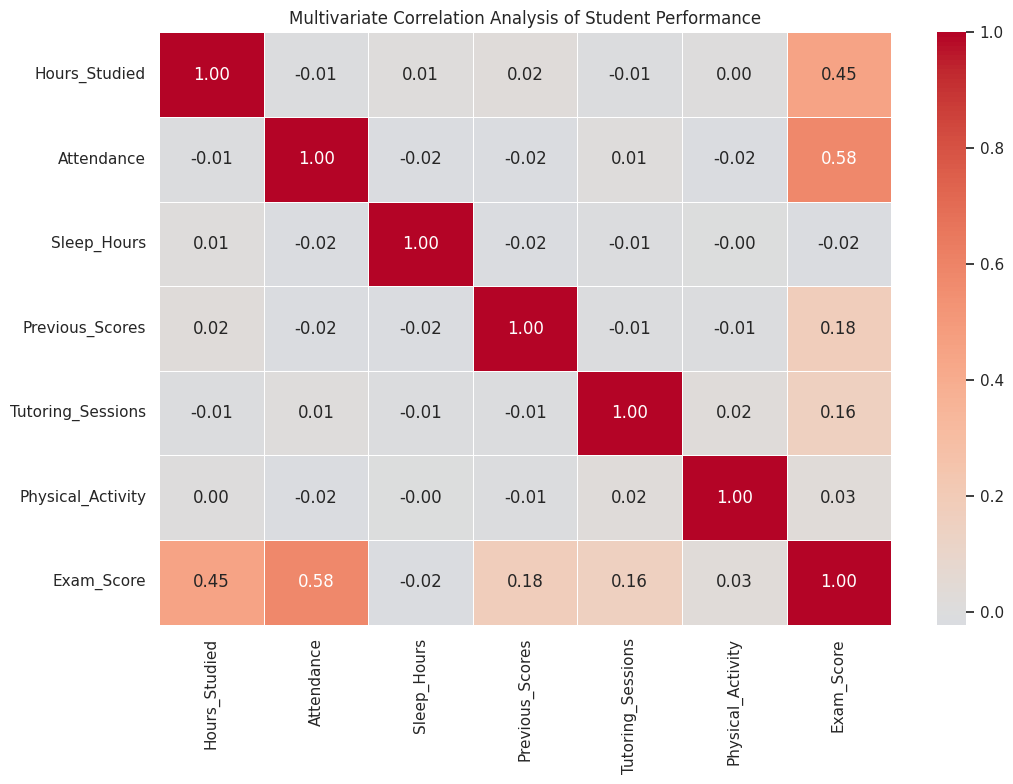

In [24]:

numeric_data = data.select_dtypes(include="number")
correlation_matrix = numeric_data.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Multivariate Correlation Analysis of Student Performance")
plt.tight_layout()
plt.show()



### Statistical Interpretation and Findings,

In [26]:
print("===== STUDENT PERFORMANCE: KEY FINDINGS =====")

# 1. Overall exam score statistics
print("\n1. Exam Score Statistics")
print("Mean:", round(data["Exam_Score"].mean(), 2))
print("Median:", round(data["Exam_Score"].median(), 2))
print("Standard deviation:", round(data["Exam_Score"].std(), 2))
print("Minimum:", data["Exam_Score"].min())
print("Maximum:", data["Exam_Score"].max())

# 2. Numerical features most correlated with exam score
numeric_df = data.select_dtypes(include="number")
correlations = numeric_df.corr()["Exam_Score"].drop("Exam_Score")
print("\n2. Top positive correlations with Exam Score")
display(correlations.sort_values(ascending=False).head(5).round(3))

# 3. Average score by teacher quality
print("\n3. Average Exam Score by Teacher Quality")
display(
    data.groupby("Teacher_Quality")["Exam_Score"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)

# 4. Average score by motivation
print("\n4. Average Exam Score by Motivation Level")
display(
    data.groupby("Motivation_Level")["Exam_Score"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)

===== STUDENT PERFORMANCE: KEY FINDINGS =====

1. Exam Score Statistics
Mean: 67.24
Median: 67.0
Standard deviation: 3.89
Minimum: 55
Maximum: 101

2. Top positive correlations with Exam Score


,Exam_Score
Attendance,0.581
Hours_Studied,0.445
Previous_Scores,0.175
Tutoring_Sessions,0.157
Physical_Activity,0.028



3. Average Exam Score by Teacher Quality


,count,mean,median,std
Teacher_Quality,,,,
High,1947,67.68,68.0,3.98
Low,657,66.75,67.0,3.87
Medium,4003,67.10,67.0,3.83



4. Average Exam Score by Motivation Level


,count,mean,median,std
Motivation_Level,,,,
High,1319,67.70,67.0,3.88
Low,1937,66.75,67.0,3.96
Medium,3351,67.33,67.0,3.83


### Statistical Findings and Interpretation

The statistical analysis of the Student Performance Factors dataset revealed that the mean exam score was 67.24, with a median of 67 and a standard deviation of 3.89. Among the numerical features, attendance had the strongest positive correlation with exam scores (r = 0.581), followed by hours studied (r = 0.445). Previous scores and tutoring sessions showed weaker positive correlations. Categorical comparisons indicated that the high teacher-quality group had a mean exam score of 67.68, while the high motivation group had a mean of 67.70. These findings suggest that attendance, study time, perceived teacher quality, and motivation are useful factors to investigate when exploring student performance. However, the descriptive comparisons do not establish causation or statistical significance.

In [28]:
print("Average Exam Score by School Type")

display(
    data.groupby("School_Type")["Exam_Score"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)


Average Exam Score by School Type


,count,mean,median,std
School_Type,,,,
Private,2009,67.29,67.0,3.85
Public,4598,67.21,67.0,3.91


### Neural Network Model

In [36]:
df_clean = data.copy()
df_clean = df_clean[df_clean["Exam_Score"] != 101].copy()

print("Records remaining:", len(df_clean))
print("Maximum exam score:", df_clean["Exam_Score"].max())

Records remaining: 6606
Maximum exam score: 100


In [38]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the cleaned dataset if available; otherwise, reuse df
data = df_clean.copy() if "df_clean" in globals() else df.copy()

# Separate input features and target
X = data.drop(columns=["Exam_Score"])
y = data["Exam_Score"]

# Identify numeric and categorical columns
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# Split before fitting preprocessing to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Preprocess numeric and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_cols),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays for TensorFlow
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
    X_test_processed = X_test_processed.toarray()

X_train_processed = X_train_processed.astype("float32")
X_test_processed = X_test_processed.astype("float32")

y_train = y_train.to_numpy(dtype="float32")
y_test = y_test.to_numpy(dtype="float32")

print("Dataset shape:", data.shape)
print("Training features:", X_train_processed.shape)
print("Testing features:", X_test_processed.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)
print("TensorFlow version:", tf.__version__)

Dataset shape: (6606, 20)
Training features: (5284, 40)
Testing features: (1322, 40)
Training target: (5284,)
Testing target: (1322,)
TensorFlow version: 2.21.0


In [39]:

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

# Build the neural network
model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)  # Predict a numerical exam score
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,737 (18.50 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 2286.5557 - mae: 41.1738 - val_loss: 18.7712 - val_mae: 3.3152
Epoch 2/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 36.4451 - mae: 4.6505 - val_loss: 7.3208 - val_mae: 1.4333
Epoch 3/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 33.0084 - mae: 4.4145 - val_loss: 5.7254 - val_mae: 0.9120
Epoch 4/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 30.4154 - mae: 4.1964 - val_loss: 5.4779 - val_mae: 0.7561
Epoch 5/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 30.9037 - mae: 4.2445 - val_loss: 5.2300 - val_mae: 0.6660
Epoch 6/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 29.6106 - mae: 4.1256 - val_loss: 5.1257 - val_mae: 0.6593
Epoch 7/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 28.5234 - mae: 4.1117 - val_loss: 5.3307 - val_mae: 0.6745
Epoch 8/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 27.8879 - mae: 4.0798 - val_loss: 5.1510 - val_mae: 0.7420
Epoch 9/100
133/133 ━━━━━━━━━━━━━━━━

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict exam scores for unseen test data
y_pred = model.predict(X_test_processed).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Deep Learning Model Evaluation")
print("-" * 35)
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Deep Learning Model Evaluation
-----------------------------------
MAE:  0.5491
RMSE: 1.5690
R² Score: 0.8139


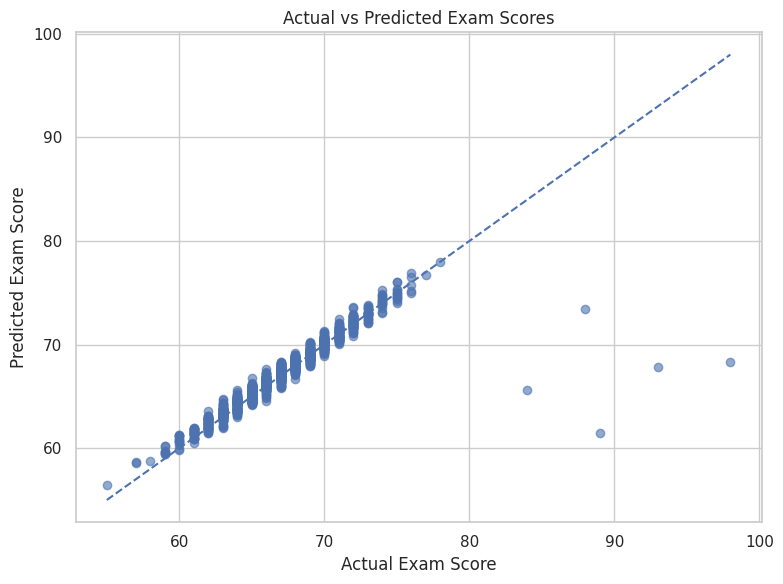

In [42]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Reference line for perfect predictions
min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle="--"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Exam Scores")
plt.tight_layout()
plt.show()


### **Actual vs. Predicted Exam Scores:** The scatter plot shows that most predicted exam scores are close to the corresponding actual scores, indicating good predictive performance on the test dataset. This visual observation is consistent with the model's R² score of 0.8139. However, some prediction errors remain, so further evaluation and hyperparameter tuning are needed.

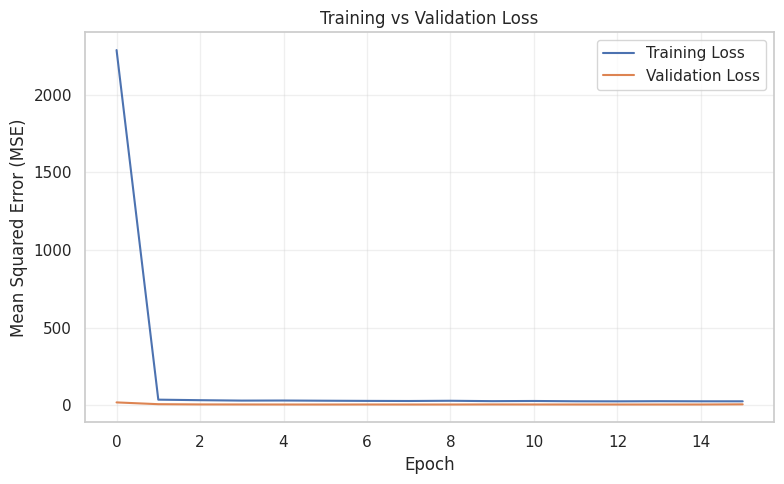

In [43]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### **Training and Validation Loss Analysis:** The training loss decreases sharply during the initial epochs and subsequently stabilizes at a low value. The validation loss also decreases and remains relatively stable, suggesting that the model learns useful patterns and shows no obvious sign of severe overfitting in this plot. Further evaluation using residual analysis and test metrics is necessary to assess generalization performance.

### HyperParameter tuning

In [44]:

import tensorflow as tf
import pandas as pd
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

configs = [
    {"name": "Model 1", "units": 32, "dropout": 0.1, "lr": 0.001, "batch": 32},
    {"name": "Model 2", "units": 64, "dropout": 0.2, "lr": 0.001, "batch": 32},
    {"name": "Model 3", "units": 64, "dropout": 0.3, "lr": 0.0005, "batch": 64}
]

results = []
tuned_models = {}

for config in configs:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    tuned_model = Sequential([
        Input(shape=(X_train_processed.shape[1],)),
        Dense(config["units"], activation="relu"),
        Dropout(config["dropout"]),
        Dense(32, activation="relu"),
        Dense(1)
    ])

    tuned_model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=config["lr"]
        ),
        loss="mse",
        metrics=["mae"]
    )

    callback = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    hist = tuned_model.fit(
        X_train_processed, y_train,
        validation_split=0.2,
        epochs=100,
        batch_size=config["batch"],
        callbacks=[callback],
        verbose=0
    )

    best_val_loss = min(hist.history["val_loss"])
    best_val_mae = min(hist.history["val_mae"])

    results.append({
        "Model": config["name"],
        "Neurons": config["units"],
        "Dropout": config["dropout"],
        "Learning Rate": config["lr"],
        "Batch Size": config["batch"],
        "Best Validation Loss": best_val_loss,
        "Best Validation MAE": best_val_mae,
        "Epochs Trained": len(hist.history["loss"])
    })

    tuned_models[config["name"]] = tuned_model

results_df = pd.DataFrame(results).sort_values(
    "Best Validation Loss"
).reset_index(drop=True)

display(results_df.round(4))


,Model,Neurons,Dropout,Learning Rate,Batch Size,Best Validation Loss,Best Validation MAE,Epochs Trained
0,Model 1,32,0.1,0.0010,32,5.0379,0.6222,17
1,Model 3,64,0.3,0.0005,64,5.0556,0.5543,46
2,Model 2,64,0.2,0.0010,32,5.1538,0.6376,21


In [45]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select Model 3 based on its lowest validation MAE
best_model = tuned_models["Model 3"]

# Predict on the test dataset
y_pred_tuned = best_model.predict(X_test_processed).flatten()

# Calculate test metrics
mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
rmse_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2_tuned = r2_score(y_test, y_pred_tuned)

print("Tuned Model 3 - Test Evaluation")
print("-" * 40)
print(f"MAE:  {mae_tuned:.4f}")
print(f"RMSE: {rmse_tuned:.4f}")
print(f"R² Score: {r2_tuned:.4f}")


42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Tuned Model 3 - Test Evaluation
----------------------------------------
MAE:  0.4328
RMSE: 1.5329
R² Score: 0.8223


## Residual plot

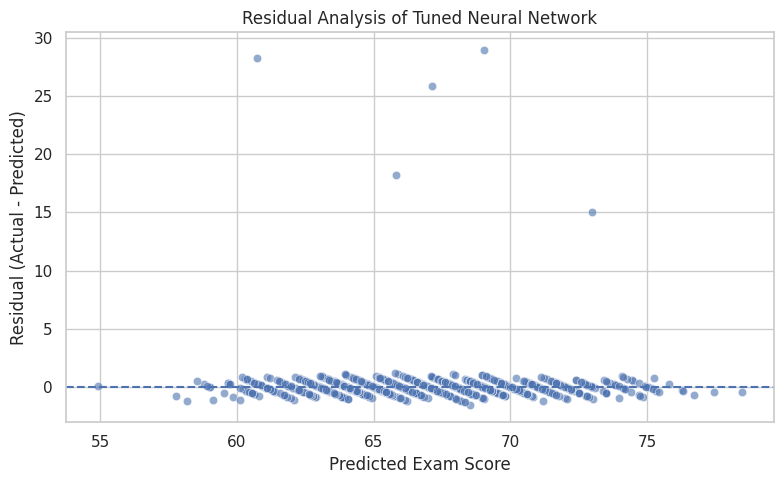

In [47]:



residuals_tuned = y_test - y_pred_tuned

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=y_pred_tuned,
    y=residuals_tuned,
    alpha=0.6
)

plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis of Tuned Neural Network")
plt.tight_layout()
plt.show()
